## Setup

In [1]:
!pip install Sastrawi

In [2]:
from collections import Counter
import copy
from itertools import combinations
import os
import random
import re
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from transformers import AutoModelForSequenceClassification, AutoTokenizer, get_linear_schedule_with_warmup

pd.set_option("display.max_colwidth", 200)
pd.set_option("display.width", 200)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
  torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Menggunakan device:", device)

Menggunakan device: cuda


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Data Collection

### Web Scraping

- **Sumber Data**: Portal berita ekonomi dan bisnis **IDX Channel** (`https://www.idxchannel.com`).
- **Metode Penentuan Label**: Label kategori ditetapkan secara otomatis (*distant supervision* berbasis struktur rubrik resmi situs) dengan mengambil artikel langsung dari 4 kanal resmi (`idkanal`), yaitu:
  - **Banking** (`idkanal=9773`, `/banking/`)
  - **Economics** (`idkanal=9772`, `/economics/`)
  - **Market News** (`idkanal=1`, `/market-news/`)
  - **Technology** (`idkanal=89397`, `/technology/`)
- **Proses Scraping**:
  1. Mengumpulkan URL artikel per kanal dengan menelusuri halaman indeks harian (`/indeks?date=...&idkanal=...`) beserta endpoint AJAX (`/indeks/more/{offset}`) mundur hingga kuota **1.100 artikel per kelas** terpenuhi (minimal 1.000 data per kelas).
  2. Mengekstrak judul (`<h1>`) dan seluruh paragraf isi berita (`<p>`) dari setiap halaman paginasi artikel, lalu menyaring artikel yang memiliki minimal 15 kata.
  3. Menggabungkan judul dan isi mentah ke kolom `raw_text`, melakukan deduplikasi awal, dan menyimpan hasil ke file CSV.

In [ ]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
from datetime import datetime, timedelta
import time
import random

# Header HTTP untuk mensimulasikan permintaan dari peramban (browser)
headers = {
    'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36'
}

# 1. Konfigurasi 4 Kanal Utama (ID & Slug URL Resmi IDX Channel)
kanals = {
    'Banking': {'id': 9773, 'slug': '/banking/'},
    'Economics': {'id': 9772, 'slug': '/economics/'},
    'Market News': {'id': 1, 'slug': '/market-news/'},
    'Technology': {'id': 89397, 'slug': '/technology/'}
}

TARGET_PER_CLASS = 1100  # Target kuota data per kelas (Total = 4.400)
all_dataset = []
start_date = datetime.now()

def extract_urls_from_html(soup, kanal_slug):
    """Menyaring URL detail berita valid dari elemen HTML"""
    urls = set()
    for link in soup.find_all('a', href=True):
        href = link['href']
        if kanal_slug in href and len(href) > len(kanal_slug) + 15:
            full_url = href if href.startswith('http') else f"https://www.idxchannel.com{href}"
            if full_url != f"https://www.idxchannel.com{kanal_slug[:-1]}":
                urls.add(full_url)
    return urls

def scrape_full_raw_article(base_url):
    """
    Mengambil judul dan seluruh isi paragraf berita mentah (raw text)
    dari semua halaman paginasi artikel (halaman 1, 2, dst.).
    """
    title = ""
    all_paragraphs = []
    page = 1
    clean_base_url = base_url.rstrip('/')

    while True:
        target_url = clean_base_url if page == 1 else f"{clean_base_url}/{page}"
        try:
            resp = requests.get(target_url, headers=headers, timeout=10)
            if resp.status_code != 200:
                break

            soup = BeautifulSoup(resp.text, 'html.parser')

            # Ekstrak judul artikel pada halaman pertama
            if page == 1:
                title_elem = soup.find('h1')
                title = title_elem.text.strip() if title_elem else ""

            # Ambil seluruh paragraf teks berita mentah apa adanya
            paragraphs = [p.text.strip() for p in soup.find_all('p') if p.text.strip()]

            if not paragraphs:
                break

            all_paragraphs.extend(paragraphs)

            # Cek jika terdapat paginasi halaman pada artikel
            page_links = [a['href'] for a in soup.find_all('a', href=True) if f"{clean_base_url}/" in a['href']]
            if page == 1 and not page_links:
                break

            page += 1
            time.sleep(0.15)

        except Exception:
            break

    raw_full_text = " ".join(all_paragraphs)
    return title, raw_full_text

# =============================================================
# PROSES FULL SCRAPING (1.100 DATA PER KELAS)
# =============================================================
print(f"MEMULAI PROSES FULL SCRAPING DATA MENTAH ({TARGET_PER_CLASS} DATA PER KELAS)...\n")

for category_name, info in kanals.items():
    print("=" * 65)
    print(f"KATEGORI: [{category_name}] (ID Kanal: {info['id']})")
    print("=" * 65)

    article_urls = set()
    current_date = start_date
    idkanal = info['id']
    kanal_slug = info['slug']
    days_checked = 0

    # --- TAHAP 1: Kumpulkan URL dari Halaman Utama Indeks + Offset AJAX ---
    print("Mengumpulkan URL artikel dari indeks harian dan endpoint AJAX...")

    while len(article_urls) < TARGET_PER_CLASS and days_checked < 600:
        date_base_fmt = current_date.strftime('%Y-%m-%d')
        date_ajax_fmt = current_date.strftime('%d-%m-%Y')
        before_count = len(article_urls)

        # 1. Scan Halaman Utama Indeks
        base_url = f"https://www.idxchannel.com/indeks?date={date_base_fmt}&idkanal={idkanal}"
        try:
            resp = requests.get(base_url, headers=headers, timeout=10)
            if resp.status_code == 200:
                soup = BeautifulSoup(resp.text, 'html.parser')
                base_links = extract_urls_from_html(soup, kanal_slug)
                article_urls.update(base_links)
        except Exception:
            # Abaikan timeout sementara dan lanjut ke AJAX/hari berikutnya
            pass

        # 2. Scan Offset AJAX jika kuota belum terpenuhi
        offset = 21
        while len(article_urls) < TARGET_PER_CLASS and offset <= 101:
            ajax_url = f"https://www.idxchannel.com/indeks/more/{offset}?idkanal={idkanal}&date={date_ajax_fmt}"
            try:
                resp = requests.get(ajax_url, headers=headers, timeout=10)
                if resp.status_code != 200 or not resp.text.strip():
                    break

                soup = BeautifulSoup(resp.text, 'html.parser')
                more_links = extract_urls_from_html(soup, kanal_slug)

                if not more_links:
                    break

                before_offset_len = len(article_urls)
                article_urls.update(more_links)

                if len(article_urls) == before_offset_len:
                    break

                offset += 20
                time.sleep(0.05)
            except Exception:
                break

        # TAMPILKAN LOG REAL-TIME PER HARI
        added_today = len(article_urls) - before_count
        print(f"   [+] Tanggal {date_base_fmt}: +{added_today} URL baru | Akumulasi: {len(article_urls)}/{TARGET_PER_CLASS}")

        current_date -= timedelta(days=1)
        days_checked += 1
        time.sleep(0.1)

    # --- TAHAP 2: Ekstraksi Konten Teks Mentah Lengkap Artikel ---
    print(f"Memuat konten berita mentah untuk kategori [{category_name}]...")
    success_count = 0

    for idx, url in enumerate(list(article_urls)[:TARGET_PER_CLASS], 1):
        title, raw_content = scrape_full_raw_article(url)

        # Validasi dasar agar artikel tidak kosong
        if title and len(raw_content.split()) >= 15:
            # Teks mentah gabungan Judul + Isi Artikel
            raw_text_combined = f"{title}. {raw_content}"

            all_dataset.append({
                'url': url,
                'title': title,
                'raw_text': raw_text_combined,
                'category': category_name
            })
            success_count += 1

        if success_count % 100 == 0 and success_count > 0:
            print(f"   Progress: {success_count}/{TARGET_PER_CLASS} artikel mentah terekstraksi...")

        time.sleep(random.uniform(0.15, 0.35))

    print(f"Kategori [{category_name}] selesai dengan total {success_count} artikel mentah!\n")

# =============================================================
# TAHAP 3: DEDUPLIKASI & SIMPAN DATASET MENTAH KE CSV
# =============================================================
df_raw = pd.DataFrame(all_dataset)
df_raw.drop_duplicates(subset=['raw_text'], inplace=True)

output_filename = 'dataset_idxchannel_raw_1100.csv'

# Menggunakan encoding='utf-8-sig' agar karakter UTF-8 aman saat dibuka di Excel/sistem manapun
df_raw.to_csv(output_filename, index=False, encoding='utf-8-sig')

print("=" * 65)
print("SCRAPING DATASET MENTAH SELESAI & BERHASIL DISIMPAN!")
print("=" * 65)
print(f"File tersimpan: '{output_filename}'")
print(f"Total baris data mentah: {len(df_raw)}")
print("\nRincian Distribusi Jumlah Data Per Kelas:")
print(df_raw['category'].value_counts())

## Exploratory Data Analysis

In [4]:
news_df = pd.read_csv('/content/drive/My Drive/College/Natural Language Processing/Tugas 2/dataset/dataset_idxchannel.csv')
news_df.head()

,url,title,raw_text,category
0,https://www.idxchannel.com/banking/bws-mobile-tambah-fitur-biometrik-perkuat-keamanan-dan-kemudahan-nasabah,"BWS Mobile Tambah Fitur Biometrik, Perkuat Keamanan dan Kemudahan Nasabah","BWS Mobile Tambah Fitur Biometrik, Perkuat Keamanan dan Kemudahan Nasabah. Scan this QR or download app from: IDXChannel – PT Bank Woori Saudara Indonesia 1906 Tbk (SDRA) atau BWS menghadirkan ino...",Banking
1,https://www.idxchannel.com/banking/ojk-catat-piutang-pembiayaan-multifinance-capai-rp5071-triliun,"OJK Catat Piutang Pembiayaan Multifinance Capai Rp507,1 Triliun","OJK Catat Piutang Pembiayaan Multifinance Capai Rp507,1 Triliun. Scan this QR or download app from: IDXChannel - Piutang pembiayaan Perusahaan Pembiayaan (PP) atau multifinance tumbuh 1,07 persen ...",Banking
2,https://www.idxchannel.com/banking/bni-wondrx-2026-tarik-100-ribu-pengunjung-transaksi-capai-rp273-triliun,"BNI wondrX 2026 Tarik 100 Ribu Pengunjung, Transaksi Capai Rp2,73 Triliun","BNI wondrX 2026 Tarik 100 Ribu Pengunjung, Transaksi Capai Rp2,73 Triliun. Scan this QR or download app from: IDXChannel - PT Bank Negara Indonesia (Persero) Tbk atau BNI menutup gelaran BNI wondr...",Banking
3,https://www.idxchannel.com/banking/bri-gelar-imlek-prosperity-2026-hadirkan-pengalaman-eksklusif-sambut-tahun-kuda-api,"BRI Gelar Imlek Prosperity 2026, Hadirkan Pengalaman Eksklusif Sambut Tahun Kuda Api","BRI Gelar Imlek Prosperity 2026, Hadirkan Pengalaman Eksklusif Sambut Tahun Kuda Api. Scan this QR or download app from: IDXChannel - PT Bank Rakyat Indonesia (Persero) Tbk (BBRI) menggelar BRI Im...",Banking
4,https://www.idxchannel.com/banking/volume-transaksi-bale-syariah-by-bsn-capai-rp284-triliun-hingga-april-2026,"Volume Transaksi Bale Syariah by BSN Capai Rp2,84 Triliun hingga April 2026","Volume Transaksi Bale Syariah by BSN Capai Rp2,84 Triliun hingga April 2026. Scan this QR or download app from: IDXChannel - PT Bank Syariah Nasional (BSN) mencatat transaksi volume Bale Syariah b...",Banking


In [5]:
for i in range(0, 10):
  print(f"artikel ke-{i}")
  print(f"{news_df['url'].iloc[i]}")
  print(f"{news_df['raw_text'].iloc[i]}\n")

artikel ke-0
https://www.idxchannel.com/banking/bws-mobile-tambah-fitur-biometrik-perkuat-keamanan-dan-kemudahan-nasabah
BWS Mobile Tambah Fitur Biometrik, Perkuat Keamanan dan Kemudahan Nasabah. Scan this QR or download app from: IDXChannel – PT Bank Woori Saudara Indonesia 1906 Tbk (SDRA) atau BWS menghadirkan inovasi layanan digital dengan meluncurkan fitur Biometric Login pada aplikasi BWS Mobile. Fitur ini memudahkan nasabah mengakses aplikasi melalui sidik jari atau pemindaian wajah tanpa perlu memasukkan kata sandi secara manual. Kehadiran fitur Biometric Login diharapkan tidak hanya meningkatkan keamanan, tetapi juga kenyamanan nasabah. Dengan sistem autentikasi biometrik, risiko penyalahgunaan akun maupun kebocoran data dapat ditekan sehingga memperkuat kepercayaan masyarakat pada layanan digital bank. Di sisi lain, kemudahan akses ini juga diharapkan mendorong nasabah semakin aktif bertransaksi melalui BWS Mobile. “Biometric Login bukan hanya soal gaya baru, tapi juga langkah

### Dataset Information

In [6]:
print("Ukuran data:", news_df.shape)
news_df.info()

print("\nMissing value:")
print(news_df.isnull().sum())

# String kosong (isna() tidak mendeteksi "")
for kolom in ["title", "raw_text", "category"]:
    kosong = (news_df[kolom].str.strip() == "").sum()
    print(f"String kosong di {kolom}: {kosong}")

# Duplikat
print("\nURL duplikat  :", news_df["url"].duplicated().sum())
print("Judul duplikat:", news_df["title"].duplicated().sum())
print("Teks duplikat :", news_df["raw_text"].duplicated().sum())

# Near-duplicate: bandingkan 200 huruf pertama (setelah dinormalisasi)
news_df["kunci_teks"] = news_df["raw_text"].str.lower().str.replace(r"[^a-z]", "", regex=True).str[:200]
print("Near-duplicate:", news_df["kunci_teks"].duplicated().sum())

# Lihat artikel yang judulnya ganda
print(news_df[news_df["title"].duplicated(keep=False)][["title", "raw_text", "category"]])

Ukuran data: (4388, 4)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4388 entries, 0 to 4387
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   url       4388 non-null   object
 1   title     4388 non-null   object
 2   raw_text  4388 non-null   object
 3   category  4388 non-null   object
dtypes: object(4)
memory usage: 137.3+ KB

Missing value:
url         0
title       0
raw_text    0
category    0
dtype: int64
String kosong di title: 0
String kosong di raw_text: 0
String kosong di category: 0

URL duplikat  : 0
Judul duplikat: 1
Teks duplikat : 0
Near-duplicate: 1
                                                                         title  \
3823  Kompetisi Inovator Muda Indonesia dalam Membentuk Masa Depan Kota Cerdas   
3950  Kompetisi Inovator Muda Indonesia dalam Membentuk Masa Depan Kota Cerdas   

                                                                                                                

### Target Distribution

category
Banking        1099
Economics      1098
Market News    1097
Technology     1094
Name: count, dtype: int64
category
Banking        25.05
Economics      25.02
Market News    25.00
Technology     24.93
Name: count, dtype: float64


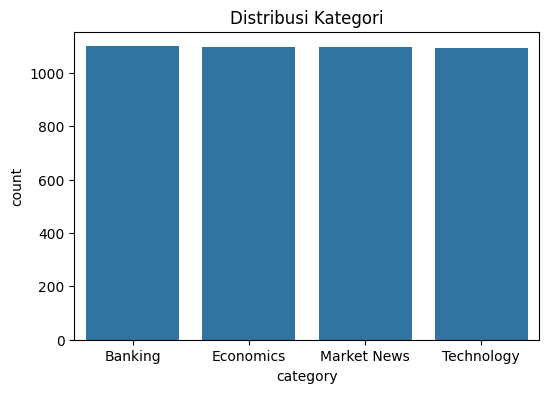

In [7]:
hitung = news_df["category"].value_counts()
print(hitung)
print((hitung / len(news_df) * 100).round(2))

plt.figure(figsize=(6, 4))
sns.countplot(data=news_df, x="category", order=hitung.index)
plt.title("Distribusi Kategori")
plt.show()

### Text Length

       jumlah_karakter  jumlah_kata  jumlah_kalimat
count      4388.000000  4388.000000     4388.000000
mean       2805.657475   381.667730       17.978578
std        1623.582213   222.091083       10.134203
min         819.000000   111.000000        1.000000
25%        1901.000000   264.000000       12.000000
50%        2519.000000   342.000000       17.000000
75%        3322.250000   449.000000       21.000000
max       40747.000000  5899.000000      260.000000


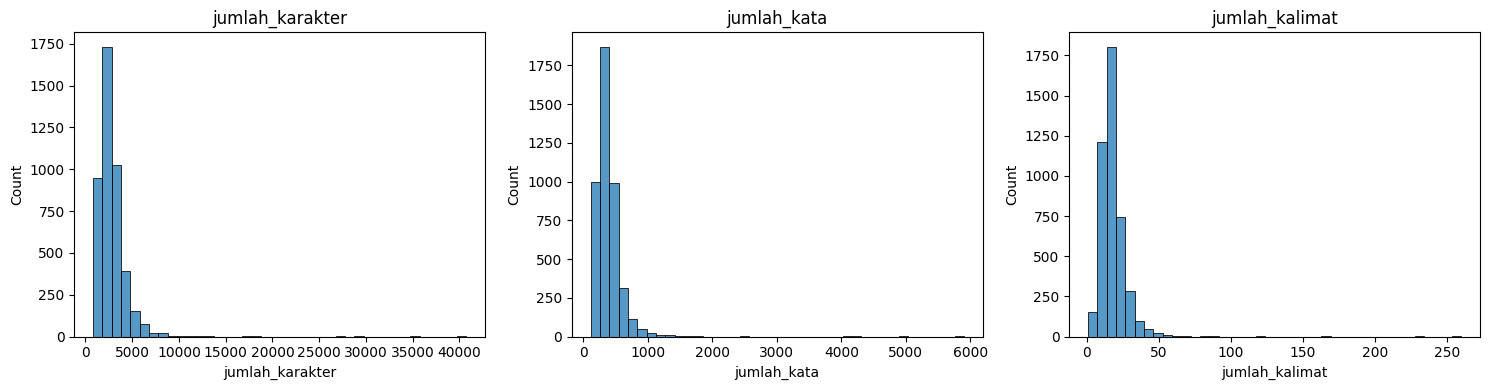

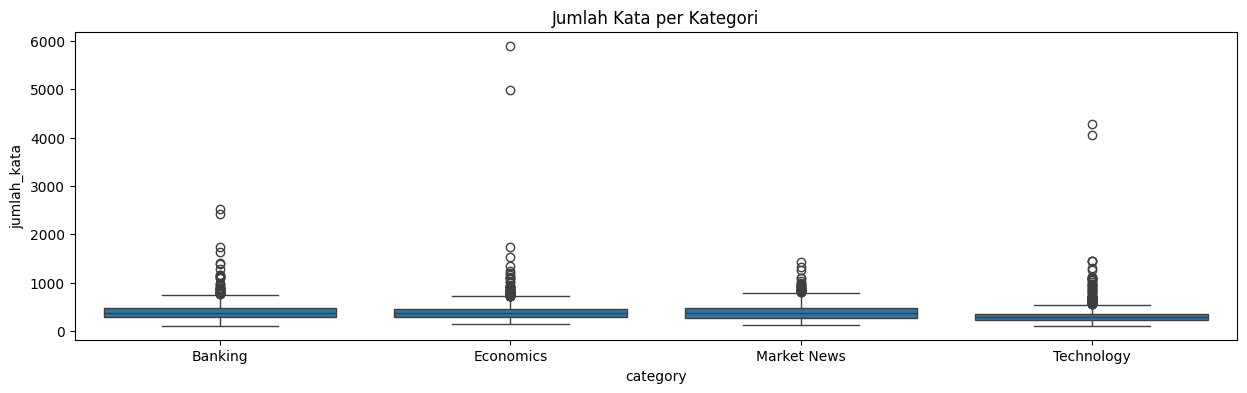

              mean  median   max
category                        
Banking      405.1   367.0  2518
Economics    409.1   368.0  5899
Market News  389.6   364.0  1434
Technology   322.6   281.5  4277
Batas atas IQR: 726.5 | Persentil 99: 1046.3900000000003 | Jumlah outlier: 176
                                                                                            title    category  jumlah_kata
1466                             AS Intervensi Yield Treasury, Suku Bunga The Fed Berpotensi Naik   Economics         5899
1341              Produksi Biofuel Global Diprediksi Melonjak 70 Persen di Tengah Konflik Timteng   Economics         4992
3621                               Ekspor Mobil Korea Selatan Melonjak 21,7 Persen pada Awal 2026  Technology         4277
3605                                           Tak Lagi Pimpin Apple, Ini Pesan Terakhir Tim Cook  Technology         4061
60    BRI Cetak Laba Rp57,132 Triliun, Komitmen Dukung Asta Cita dan Fokus Perkuat Ekonomi Rakyat     Bankin

In [8]:
news_df["jumlah_karakter"] = news_df["raw_text"].str.len()
news_df["jumlah_kata"] = news_df["raw_text"].str.split().str.len()
news_df["jumlah_kalimat"] = news_df["raw_text"].str.count(r"[.!?]\s")
print(news_df[["jumlah_karakter", "jumlah_kata", "jumlah_kalimat"]].describe())

# Histogram
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, kol in zip(axes, ["jumlah_karakter", "jumlah_kata", "jumlah_kalimat"]):
    sns.histplot(news_df[kol], bins=40, ax=ax)
    ax.set_title(kol)
plt.tight_layout()
plt.show()

# Boxplot per kategori
plt.figure(figsize=(15, 4))
sns.boxplot(data=news_df, x="category", y="jumlah_kata")
plt.title("Jumlah Kata per Kategori")
plt.show()
print(news_df.groupby("category")["jumlah_kata"].agg(["mean", "median", "max"]).round(1))

# Outlier dengan IQR dan persentil 99
Q1 = news_df["jumlah_kata"].quantile(0.25)
Q3 = news_df["jumlah_kata"].quantile(0.75)
batas_atas = Q3 + 1.5 * (Q3 - Q1)
p99 = news_df["jumlah_kata"].quantile(0.99)
outlier = news_df[news_df["jumlah_kata"] > batas_atas]
print("Batas atas IQR:", batas_atas, "| Persentil 99:", p99, "| Jumlah outlier:", len(outlier))

# Artikel terpanjang -> cek isinya
print(news_df.nlargest(5, "jumlah_kata")[["title", "category", "jumlah_kata"]])

### Analisis Noise

In [9]:
# Seberapa sering tiap pola noise muncul (dalam persen artikel)
pola = {
    "Scan this QR": r"Scan this QR",
    "IDXChannel": r"IDXChannel",
    "Baca Juga": r"Baca Juga",
    "Footer Halaman": r"Halaman\s*:",
    "Byline (Nama) di akhir": r"\([^()]*\)\s*(Halaman.*)?$",
    "Ada newline": r"\n",
    "Ada URL (http)": r"http",
}
hasil = {nama: news_df["raw_text"].str.contains(p, regex=True, flags=re.S).mean() * 100
         for nama, p in pola.items()}
print(pd.Series(hasil).round(2))

# Karakter non-ASCII yang sering muncul
semua_karakter = Counter("".join(news_df["raw_text"].tolist()))
print({k: v for k, v in semua_karakter.items() if ord(k) > 127 and v > 50})

# Angka, Rupiah, persen per kategori
news_df["ada_rp"] = news_df["raw_text"].str.contains("Rp")
news_df["ada_persen"] = news_df["raw_text"].str.contains("%")
news_df["jumlah_angka"] = news_df["raw_text"].str.count(r"\d+")
print(news_df.groupby("category")[["ada_rp", "ada_persen", "jumlah_angka"]].mean().round(2))

# Ticker saham: 4 huruf kapital dalam kurung, contoh (BBRI)
news_df["ticker"] = news_df["raw_text"].str.findall(r"\(([A-Z]{4})\)")
semua_ticker = Counter([t for daftar in news_df["ticker"] for t in daftar])
print("Ticker terbanyak:", semua_ticker.most_common(10))

/tmp/ipykernel_667/3636210063.py:11: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  hasil = {nama: news_df["raw_text"].str.contains(p, regex=True, flags=re.S).mean() * 100


Scan this QR              100.00
IDXChannel                 99.77
Baca Juga                   2.42
Footer Halaman              6.84
Byline (Nama) di akhir     96.42
Ada newline                 6.84
Ada URL (http)              0.27
dtype: float64
{'–': 952, '“': 3064, '”': 3074, '\xa0': 1971, '’': 230, '—': 307, '‘': 70, '\u200e': 177}
             ada_rp  ada_persen  jumlah_angka
category                                     
Banking        0.53        0.01         23.36
Economics      0.34        0.01         21.31
Market News    0.61        0.01         34.43
Technology     0.35        0.01         20.50
Ticker terbanyak: [('IHSG', 185), ('BBRI', 140), ('BBTN', 120), ('BMRI', 119), ('ESDM', 96), ('BBCA', 93), ('UMKM', 87), ('BBNI', 70), ('BRIS', 68), ('ANTM', 56)]


In [10]:
# Apakah ticker tertentu terkonsentrasi di satu kategori? (potensi shortcut/leakage)
baris = [(kat, t) for kat, daftar in zip(news_df["category"], news_df["ticker"]) for t in daftar]
tick_df = pd.DataFrame(baris, columns=["category", "ticker"])

top_ticker = [t for t, _ in semua_ticker.most_common(10)]
tabel_tick = pd.crosstab(tick_df["ticker"], tick_df["category"]).loc[top_ticker]
dominasi = tabel_tick.max(axis=1) / tabel_tick.sum(axis=1) * 100
tabel_tick["dominasi_%"] = dominasi.round(1)
print(tabel_tick)

category  Banking  Economics  Market News  Technology  dominasi_%
ticker                                                           
IHSG            1          1          183           0        98.9
BBRI           87          2           51           0        62.1
BBTN          117          1            2           0        97.5
BMRI           75          2           42           0        63.0
ESDM            0         83           11           2        86.5
BBCA           38          0           55           0        59.1
UMKM           49         34            2           2        56.3
BBNI           54          0           16           0        77.1
BRIS           61          1            6           0        89.7
ANTM            0          4           52           0        92.9


### Distribusi Tanggal

Artikel yang punya tanggal: 86.1 %


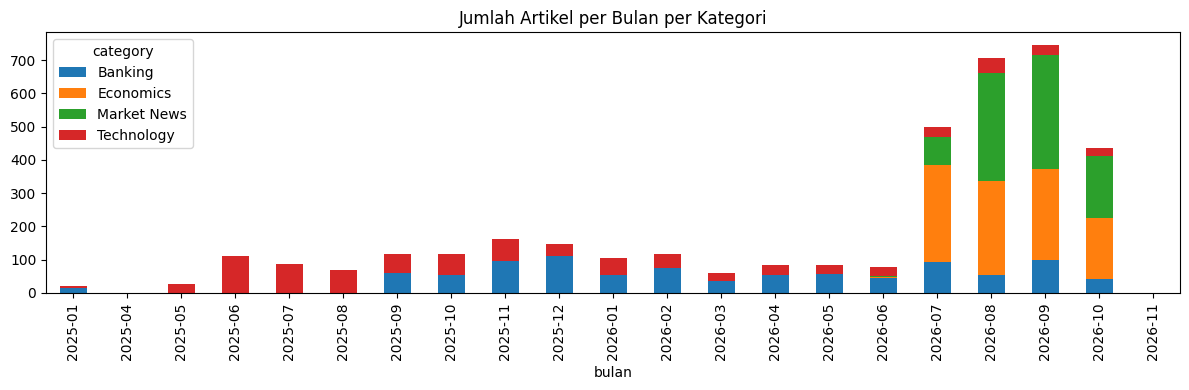

In [11]:
# Tanggal tertanam di teks, contoh: "Rabu (5/8/2026)"
pola_tgl = r"(?:Senin|Selasa|Rabu|Kamis|Jumat|Sabtu|Minggu)\s*\((\d{1,2}/\d{1,2}/\d{4})\)"
news_df["tanggal"] = pd.to_datetime(news_df["raw_text"].str.extract(pola_tgl)[0],
                               format="%d/%m/%Y", errors="coerce")
# Buang tanggal yang tidak masuk akal (salah ketik di berita)
news_df.loc[(news_df["tanggal"].dt.year < 2025) | (news_df["tanggal"].dt.year > 2026), "tanggal"] = pd.NaT
print("Artikel yang punya tanggal:", round(news_df["tanggal"].notna().mean() * 100, 1), "%")

news_df["bulan"] = news_df["tanggal"].dt.to_period("M").astype(str)
tabel = pd.crosstab(news_df["bulan"], news_df["category"])
tabel = tabel[tabel.index != "NaT"]
tabel.plot(kind="bar", stacked=True, figsize=(12, 4))
plt.title("Jumlah Artikel per Bulan per Kategori")
plt.tight_layout()
plt.show()

### Frekuensi Kata

In [12]:
teks_mentah = news_df["raw_text"].str.lower().str.replace(r"[^a-z\s]", " ", regex=True)
display(Counter(" ".join(teks_mentah).split()).most_common(20))

[('yang', 34424),
 ('dan', 31939),
 ('di', 24092),
 ('pada', 15878),
 ('dengan', 15402),
 ('dari', 14922),
 ('untuk', 14872),
 ('ini', 14677),
 ('persen', 13913),
 ('dalam', 13456),
 ('rp', 11056),
 ('qr', 10853),
 ('app', 10845),
 ('from', 10810),
 ('or', 10805),
 ('download', 10803),
 ('scan', 10801),
 ('this', 10799),
 ('tersebut', 10647),
 ('menjadi', 9016)]

## Data Preprocessing

In [13]:
df = news_df[["url", "title", "raw_text", "category"]].copy()
jumlah_awal = len(df)
print("Jumlah awal:", jumlah_awal)

Jumlah awal: 4388


### Penghapusan Duplikat

Artikel duplikat dibuang berdasarkan `raw_text` dan `title`. Duplikat membuat artikel yang sama bisa muncul sekaligus di data latih dan data uji, sehingga performa model terlihat lebih tinggi dari kemampuan generalisasi sebenarnya (data leakage). Pada tahap ini hanya 1 artikel yang dibuang (4.388 → 4.387), sejalan dengan hasil EDA bahwa duplikat sangat sedikit. Deduplikasi dilakukan **lagi setelah cleaning**, karena dua artikel yang berbeda hanya pada byline atau footer akan menjadi identik setelah dibersihkan.

In [14]:
sebelum = len(df)
# Hapus duplikat berdasarkan raw_text dan title
df = df.drop_duplicates(subset=["raw_text"])
df = df.drop_duplicates(subset=["title"])
df = df.sort_index().reset_index(drop=True)

print("Duplikat dihapus:", sebelum - len(df))
print("Sisa data:", len(df))

Duplikat dihapus: 1
Sisa data: 4387


### Fungsi Cleaning

Fungsi `bersihkan()` menghapus teks yang berasal dari templat situs, bukan dari isi berita. Daftar polanya disusun dari analisis noise pada EDA:

| Noise | Alasan dibuang |
|---|---|
| Kalimat "Scan this QR..." + dateline | Ada di 100% artikel, tidak membawa informasi topik |
| Byline, `Reporter:`, `Editor:` | Nama penulis bisa menjadi *shortcut* yang tidak terkait topik |
| Footer `Halaman`, `Baca Juga`, `Disclaimer` | Elemen navigasi, bukan isi artikel |
| Judul yang terulang di awal teks | Sudah ada di kolom `title` |
| URL, `\xa0`, karakter zero-width | Karakter tak terlihat yang merusak tokenisasi |

Tanpa pembersihan, kata `scan`, `qr`, `app`, dan `download` masuk 20 kata teratas dengan frekuensi sekitar 10.800 kali, sedangkan byline ditemukan di 96,42% artikel.

Efeknya terukur: rata-rata jumlah kata turun 14,15% (paling besar pada Technology, 23,14%). Persentase artikel yang masih memuat pola noise sebelum dan sesudah cleaning ditampilkan pada tabel di bagian *Eksplorasi Data setelah Cleaning*.

In [15]:
def bersihkan(raw, title, mask_tanggal=True):
    # Karakter tak terlihat: nbsp dan semua karakter zero-width
    t = raw.replace("\xa0", " ").strip()
    t = re.sub(r"[\u200b-\u200f\u2060\ufeff]", "", t)

    # URL
    t = re.sub(r"https?://\S+|www\.\S+", " ", t)

    # Judul ganda: judul sudah ada di kolom title
    if t.startswith(title):
        t = t[len(title):]

    # Footer halaman: buang footer pertama serta semua teks sesudahnya
    t = re.split(r"Halaman\s*:\s*\d", t, maxsplit=1)[0]

    # Baca Juga: buang label beserta judul berita di baris berikutnya
    t = re.sub(r"Baca Juga\s*:?\s*\n+[^\n]*\n?", " ", t)
    t = re.sub(r"Baca Juga\s*:?", " ", t)

    # Disclaimer
    t = re.sub(r"Disclaimer\s*:[^.]*\.?", " ", t)

    # Reporter dan Editor
    t = re.sub(r"\(\s*Reporter\s*:[^)]*\)", " ", t)
    t = re.sub(r"Reporter\s*:\s*[A-Za-z .'’]{3,40}?(?=\s*(?:Editor\s*:|\(|$))", " ", t)
    t = re.sub(r"Editor\s*:\s*[A-Za-z .'’]{3,40}", " ", t)

    # Nama penulis setelah akhir kalimat, diikuti kalimat QR atau akhir teks
    for _ in range(2):
        t = re.sub(r"(?<=[.!?\"”’'])\s*\([A-Za-z'’./ ]{3,40}\)(?=\s*(?:Scan this QR|$))", " ", t.strip())

    # Kalimat QR beserta dateline
    t = re.sub(r"Scan this QR or download app from\s*:?\s*"
                r"(?:(?:[A-Za-z]*chan+e*l*[A-Za-z]*|[A-Z][A-Z ]{2,20})\s*[-–—]\s*)?",
                " ", t, flags=re.I)

    # Nama penulis yang baru berada di ujung teks setelah kalimat QR dibuang
    for _ in range(2):
        t = re.sub(r"(?<=[.!?\"”’'])\s*\([A-Za-z'’./ ]{3,40}\)\s*$", " ", t.strip())

    # Sisa dateline di awal dan di tengah teks
    t = re.sub(r"^[\s.:]*(?:idx\w*)?\s*[-–—:]\s*", "", t, flags=re.I)
    t = re.sub(r"(?<![\w-])[A-Za-z]*chan+e*l*\s*[-–—]\s+", " ", t, flags=re.I)

    # Tanggal dan tahun
    if mask_tanggal:
        t = re.sub(r"(?:[A-Za-z]+\s*)?\(?\d{1,2}/\d{1,2}/\d{2,4}\)?", " ", t)
        t = re.sub(r"\b(?:19|20)\d{2}(?:[-/](?:19|20)\d{2})?\b", " ", t)

    # Sisa tanda baca akibat penghapusan
    t = re.sub(r"\s+([,.;:!?])", r"\1", t)
    t = re.sub(r"([,;:])(?:\s*[,;:])+", r"\1", t)
    t = re.sub(r",\s*\.", ".", t)

    # Mengganti karakter whitespace ganda menjadi satu spasi
    return re.sub(r"\s+", " ", t).lstrip(" .,-–—:").strip()

In [16]:
# Teks bersih
df = df.dropna(subset=["title", "raw_text", "category"]).reset_index(drop=True)
df["teks_bersih"] = [bersihkan(r, t) for r, t in zip(df["raw_text"], df["title"])]

# Buang artikel yang kosong setelah dibersihkan
df = df[df["teks_bersih"].str.len() > 0].reset_index(drop=True)

# ===== TAMBAHAN: pembersihan pasca-cleaning =====
# Teks identik dengan kategori berbeda = label ambigu, buang semua salinannya
konflik = df.groupby("teks_bersih")["category"].nunique()
teks_konflik = konflik[konflik > 1].index
print("Teks sama tapi kategori beda:", len(teks_konflik))
df = df[~df["teks_bersih"].isin(teks_konflik)]

# Deduplikasi ulang setelah cleaning (byline/footer sudah hilang)
sebelum = len(df)
df = df.drop_duplicates(subset=["teks_bersih"])
print("Duplikat pasca-cleaning dibuang:", sebelum - len(df))

# Buang artikel yang terlalu pendek setelah cleaning (sesuaikan ambang dengan EDA)
MIN_KATA = 20
sebelum = len(df)
df = df[df["teks_bersih"].str.split().str.len() >= MIN_KATA]
print(f"Artikel < {MIN_KATA} kata dibuang:", sebelum - len(df))

df = df.reset_index(drop=True)
print("Sisa data:", len(df))
# ===== AKHIR TAMBAHAN =====

# Label numerik
nama_kelas = sorted(df["category"].unique())
label2id = {k: i for i, k in enumerate(nama_kelas)}
id2label = {i: k for k, i in label2id.items()}
df["label"] = df["category"].map(label2id)
jumlah_kelas = len(nama_kelas)
print("Kelas:", label2id)

Teks sama tapi kategori beda: 0
Duplikat pasca-cleaning dibuang: 0
Artikel < 20 kata dibuang: 0
Sisa data: 4387
Kelas: {'Banking': 0, 'Economics': 1, 'Market News': 2, 'Technology': 3}


Setelah cleaning dilakukan tiga pemeriksaan ulang karena cleaning bisa mengubah kondisi data:

- **Teks identik dengan kategori berbeda** dibuang seluruhnya karena labelnya ambigu dan memberi sinyal yang saling bertentangan ke model. Hasil: 0 kasus.
- **Deduplikasi ulang** pada `teks_bersih`. Hasil: 0 duplikat baru.
- **Artikel terlalu pendek** (`MIN_KATA = 20`) dibuang karena tidak cukup informasi untuk klasifikasi. Hasil: 0 artikel (panjang minimum sebelum cleaning sudah 111 kata).

Jumlah akhir tetap 4.387 artikel dengan 4 kelas: Banking, Economics, Market News, Technology.

### Data Splitting

Data dibagi **70% train / 15% validation / 15% test** (3.070 / 658 / 659) dengan `stratify` pada label dan `random_state=42`.

- **Stratified**: proporsi tiap kelas dijaga sama di semua subset. Selisih proporsi maksimum terhadap data penuh hanya 0,09 poin persen, sehingga metrik macro tidak bias akibat distribusi kelas yang berbeda antar subset.
- **Validation** dipakai untuk *early stopping* dan pemilihan epoch terbaik.
- **Test** hanya dipakai sekali pada evaluasi akhir, tidak untuk menentukan hyperparameter, agar estimasi performanya tidak bias.
- Pembagian dilakukan **sebelum** vocabulary dan statistik apa pun dihitung, sehingga tidak ada informasi dari validation/test yang masuk ke proses pelatihan.

In [17]:
# Split 70/15/15
train_df, sisa_df = train_test_split(df, test_size=0.30, stratify=df["label"], random_state=SEED)
val_df, test_df = train_test_split(sisa_df, test_size=0.50, stratify=sisa_df["label"], random_state=SEED)
train_df, val_df, test_df = [d.reset_index(drop=True) for d in (train_df, val_df, test_df)]

print("Ukuran -> train:", len(train_df), "| val:", len(val_df), "| test:", len(test_df))

# Cek proporsi kelas di tiap split (dalam persen)
proporsi = pd.DataFrame({
    "semua": df["category"].value_counts(normalize=True),
    "train": train_df["category"].value_counts(normalize=True),
    "val":   val_df["category"].value_counts(normalize=True),
    "test":  test_df["category"].value_counts(normalize=True),
}).mul(100).round(2)
print(proporsi)

selisih_maks = float(proporsi[["train", "val", "test"]].sub(proporsi["semua"], axis=0).abs().max().max())
print("Selisih proporsi maksimum:", round(selisih_maks, 2), "poin persen")
if selisih_maks > 1:
    print("PERINGATAN: proporsi kelas tidak sama, periksa parameter stratify.")

Ukuran -> train: 3070 | val: 658 | test: 659
             semua  train    val   test
category                               
Banking      25.05  25.05  25.08  25.04
Economics    25.03  25.02  25.08  25.04
Market News  25.01  25.02  24.92  25.04
Technology   24.91  24.92  24.92  24.89
Selisih proporsi maksimum: 0.09 poin persen


## Eksplorasi Data setelah Cleaning

Rata-rata jumlah kata sebelum vs sesudah cleaning:
             kata_raw  kata_bersih  reduksi_%
category                                     
Banking         405.1        360.5      11.01
Economics       409.1        352.3      13.88
Market News     389.6        349.5      10.29
Technology      322.4        247.8      23.14
Semua           381.6        327.6      14.15 

Persentase artikel yang masih memuat pola noise:
                    raw_text_%  teks_bersih_%
Scan this QR            100.00           0.00
IDXChannel               99.82           1.46
Baca Juga                 2.42           0.00
Footer Halaman            6.84           0.00
Reporter/Editor           1.14           0.00
Disclaimer                2.23           0.00
URL                       0.46           0.00
Tanggal dd/mm/yyyy       87.83           0.00
Tahun 19xx/20xx          97.67           0.00
Karakter nbsp/ZW         23.25           0.00
Newline                   6.84           0.00 



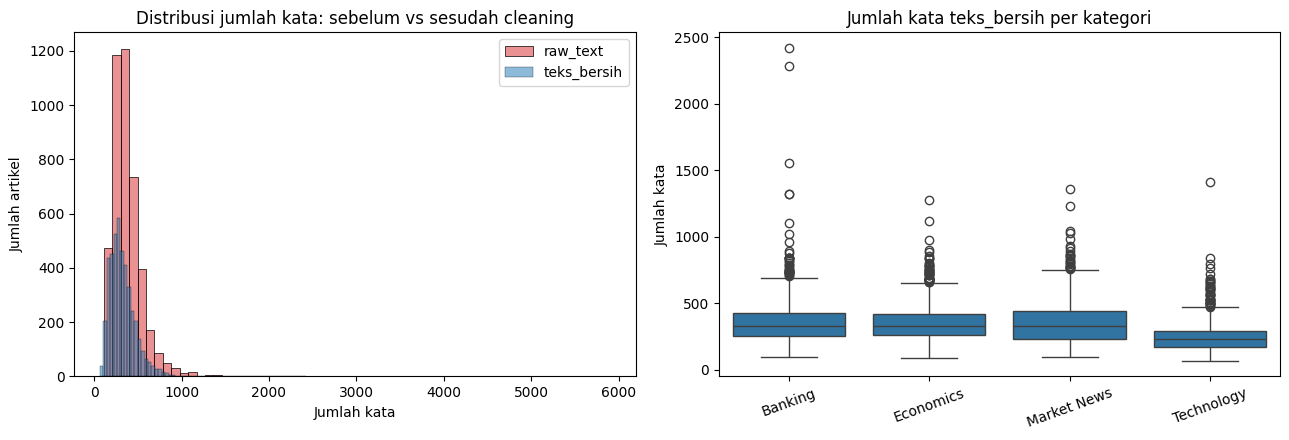

In [18]:
df["kata_raw"]    = df["raw_text"].str.split().str.len()
df["kata_bersih"] = df["teks_bersih"].str.split().str.len()

ringkas = df.groupby("category")[["kata_raw", "kata_bersih"]].mean().round(1)
ringkas.loc["Semua"] = df[["kata_raw", "kata_bersih"]].mean().round(1)
ringkas["reduksi_%"] = ((1 - ringkas["kata_bersih"] / ringkas["kata_raw"]) * 100).round(2)
print("Rata-rata jumlah kata sebelum vs sesudah cleaning:")
print(ringkas, "\n")

pola_noise = {
    "Scan this QR":       r"scan this qr",
    "IDXChannel":         r"idx\s*channel",
    "Baca Juga":          r"baca juga",
    "Footer Halaman":     r"halaman\s*:\s*\d",
    "Reporter/Editor":    r"\b(?:reporter|editor)\s*:",
    "Disclaimer":         r"disclaimer\s*:",
    "URL":                r"https?://|www\.",
    "Tanggal dd/mm/yyyy": r"\d{1,2}/\d{1,2}/\d{2,4}",
    "Tahun 19xx/20xx":    r"\b(?:19|20)\d{2}\b",
    "Karakter nbsp/ZW":   r"[\xa0\u200e\u200b]",
    "Newline":            r"\n",
}
sisa_noise = pd.DataFrame({
    nama: [df["raw_text"].str.contains(p, case=False, regex=True).mean() * 100,
           df["teks_bersih"].str.contains(p, case=False, regex=True).mean() * 100]
    for nama, p in pola_noise.items()
}, index=["raw_text_%", "teks_bersih_%"]).T.round(2)
print("Persentase artikel yang masih memuat pola noise:")
print(sisa_noise, "\n")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(df["kata_raw"], bins=60, color="tab:red", alpha=.5, label="raw_text", ax=ax[0])
sns.histplot(df["kata_bersih"], bins=60, color="tab:blue", alpha=.5, label="teks_bersih", ax=ax[0])
ax[0].set(title="Distribusi jumlah kata: sebelum vs sesudah cleaning", xlabel="Jumlah kata", ylabel="Jumlah artikel")
ax[0].legend()
sns.boxplot(data=df, x="category", y="kata_bersih", order=nama_kelas, ax=ax[1])
ax[1].set(title="Jumlah kata teks_bersih per kategori", xlabel="", ylabel="Jumlah kata")
ax[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

In [19]:
display(df['teks_bersih'].head(5))

,teks_bersih
0,PT Bank Woori Saudara Indonesia Tbk (SDRA) atau BWS menghadirkan inovasi layanan digital dengan meluncurkan fitur Biometric Login pada aplikasi BWS Mobile. Fitur ini memudahkan nasabah mengakses a...
1,"Piutang pembiayaan Perusahaan Pembiayaan (PP) atau multifinance tumbuh 1,07 persen yoy pada September menjadi Rp507,14 triliun. Hal ini didukung pembiayaan modal kerja yang tumbuh sebesar 10,61 pe..."
2,"PT Bank Negara Indonesia (Persero) Tbk atau BNI menutup gelaran BNI wondrX setelah berlangsung selama tiga hari pada 21-23 Agustus di Indonesia Convention Exhibition (ICE) BSD, Tangerang. Mengusun..."
3,"PT Bank Rakyat Indonesia (Persero) Tbk (BBRI) menggelar BRI Imlek Prosperity di Hotel Mulia, Jakarta (20/2).Mengusung semangat Tahun Baru Imlek yang dikenal sebagai Tahun Kuda Api, kegiatan ini me..."
4,"PT Bank Syariah Nasional (BSN) mencatat transaksi volume Bale Syariah by BSN sebesar Rp2,84 triliun dari 1,2 juta transaksi hingga April. Adapun pada sisi penyaluran pembiayaan BSN tumbuh 22 perse..."


In [20]:
from sklearn.feature_selection import chi2
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

stop_id = set(StopWordRemoverFactory().get_stop_words())

def token_dasar(t):
    return [w for w in re.sub(r"[^a-z\s]", " ", t.lower()).split()
            if w not in stop_id and len(w) > 2]

# (a) Kata terbanyak per kategori, tanpa stopword (data train)
print("=== Top 10 kata per kategori ===")
for k in nama_kelas:
    cnt_k = Counter(w for t in train_df.loc[train_df["category"] == k, "teks_bersih"]
                    for w in token_dasar(t))
    print(f"{k:<15}", cnt_k.most_common(10))

# (b) Kata/bigram paling diskriminatif per kelas (chi-square)
vec = CountVectorizer(min_df=5, ngram_range=(1, 2))
X = vec.fit_transform(train_df["teks_bersih"].str.lower())
terms = np.array(vec.get_feature_names_out())
print("\n=== Top 15 term diskriminatif (chi2) ===")
for k, nama in id2label.items():
    skor, _ = chi2(X, (train_df["label"] == k).astype(int))
    top = terms[np.argsort(np.nan_to_num(skor))[-15:][::-1]]
    print(f"{nama:<15}", list(top))

# (c) Cek kebocoran: seberapa sering nama kategori muncul di teks
print("\n=== Kemunculan nama kategori di teks (% artikel) ===")
bocor = []
for k in nama_kelas:
    ada = train_df["teks_bersih"].str.contains(k, case=False, regex=False)
    bocor.append({"kategori": k,
                  "di_kelas_sendiri_%": round(ada[train_df["category"] == k].mean() * 100, 1),
                  "di_kelas_lain_%": round(ada[train_df["category"] != k].mean() * 100, 1)})
print(pd.DataFrame(bocor).set_index("kategori"))

# (d) Statistik panjang sekuens (dasar penentuan max_len)
panjang_kata = train_df["teks_bersih"].str.split().str.len()
print("\n=== Panjang teks_bersih (kata, data train) ===")
print(panjang_kata.describe(percentiles=[.5, .9, .95, .99]).round(1))

=== Top 10 kata per kategori ===
Banking         [('bank', 3037), ('persen', 2807), ('indonesia', 1812), ('menjadi', 1704), ('tersebut', 1513), ('sebesar', 1402), ('keuangan', 1343), ('triliun', 1334), ('kredit', 1306), ('melalui', 1279)]
Economics       [('tersebut', 2042), ('indonesia', 1790), ('menjadi', 1535), ('persen', 1515), ('pemerintah', 1354), ('lebih', 1066), ('ekonomi', 1013), ('hingga', 974), ('negara', 945), ('melalui', 895)]
Market News     [('persen', 3705), ('saham', 3466), ('tersebut', 2294), ('menjadi', 1838), ('pasar', 1709), ('harga', 1703), ('tbk', 1414), ('perseroan', 1213), ('indonesia', 1132), ('lebih', 1088)]
Technology      [('tersebut', 1401), ('perusahaan', 1083), ('lebih', 1020), ('persen', 956), ('indonesia', 950), ('tahun', 884), ('menjadi', 880), ('mobil', 862), ('usd', 673), ('baru', 668)]

=== Top 15 term diskriminatif (chi2) ===
Banking         ['bank', 'kredit', 'bri', 'nasabah', 'yoy', 'perbankan', 'persen yoy', 'btn', 'pembiayaan', 'bni', 'bi', 'm

## Per Model Preprocessing

### CNN/BiGRU

CNN dan BiGRU dilatih dari awal (embedding diinisialisasi acak), sehingga teks harus diubah menjadi urutan token yang ringkas dan konsisten. Tahapannya:

1. **Case folding**: "Bank" dan "bank" dianggap satu kata, mengurangi ukuran vocabulary.
2. **Normalisasi angka, Rp, dan persen** menjadi token khusus (`<uang>`, `<persen>`). Nilai spesifik seperti "1,07" atau "Rp507,14" hampir selalu unik dan jarang berulang, sehingga tidak dipelajari baik oleh embedding. Yang informatif adalah *keberadaan* nilai uang atau persen, yang pola kemunculannya berbeda antar kelas (misal angka lebih banyak pada Market News: rata-rata 34,43 angka per artikel vs sekitar 20-23 pada kelas lain).
3. **Penghapusan tanda baca dan karakter non-huruf** agar token tidak terpecah oleh simbol.
4. **Stopword removal** (daftar Sastrawi). Kata seperti "yang", "dan", "di" mendominasi frekuensi di semua kelas (lihat EDA) tetapi tidak membedakan topik. Pada model yang dilatih dari nol dengan panjang input terbatas, membuangnya menghemat posisi urutan untuk kata yang lebih informatif.
5. **Stemming tidak digunakan.** Stemmer Sastrawi lambat pada korpus ini, dan untuk klasifikasi topik, kata berimbuhan yang berbeda biasanya tetap berasal dari ranah yang sama. Stemming juga berisiko salah memotong nama entitas dan emiten saham. Pengaruhnya terhadap akurasi tidak diuji, jadi ini menjadi keterbatasan.

Setelah tokenisasi, token diubah menjadi indeks angka lewat vocabulary:

- **Vocabulary hanya dibangun dari data train.** Jika validation/test ikut dihitung, informasi dari data evaluasi bocor ke model. Kata yang tidak ada di train dipetakan ke `<UNK>`.
- **`MAX_VOCAB` = 20.000 dan `MIN_FREQ` = 2.** Dari 26.507 kata unik di train, kata yang hanya muncul sekali (banyak berupa salah ketik atau nama langka) tidak dipelajari baik dan hanya memperbesar embedding, sehingga vocabulary akhir 17.056 kata.
- **`MAX_LEN_SEQ` = 300.** CNN dan BiGRU membutuhkan panjang input seragam. Urutan yang lebih pendek diberi `<PAD>`, yang lebih panjang dipotong. Nilai 300 dipilih untuk mencakup mayoritas panjang artikel setelah *stopword removal* secara efisien.
- **Input berupa judul + isi** (`teks_input`), karena judul berita ringkas dan padat topik.

In [21]:
# 1. Gabungkan judul dan teks bersih agar sinyal topik dari judul ikut dipelajari
for split_df in (train_df, val_df, test_df):
  split_df["teks_input"] = (
      split_df["title"].str.strip() + ". " + split_df["teks_bersih"].str.strip()
  )

# 2. Stopword daftar Bahasa Indonesia (Sastrawi) untuk analisis TF-IDF & tokenisasi
stop_factory = StopWordRemoverFactory()
stopwords_id = set(stop_factory.get_stop_words())


def tokenisasi_klasik(teks):
  # Case folding & normalisasi angka/simbol
  teks = teks.lower()
  teks = re.sub(r"\brp[\d.,]+", " <uang> ", teks)
  teks = re.sub(r"\b\d+(?:[.,]\d+)?\s*(?:persen|%)", " <persen> ", teks)
  teks = re.sub(r"[^a-z<>_\s]", " ", teks)
  tokens = [
      w for w in teks.split() if len(w) > 1 and w not in stopwords_id
  ]
  return tokens


# Terapkan tokenisasi pada setiap split
train_tokens = [tokenisasi_klasik(t) for t in train_df["teks_input"]]
val_tokens = [tokenisasi_klasik(t) for t in val_df["teks_input"]]
test_tokens = [tokenisasi_klasik(t) for t in test_df["teks_input"]]

# 3. Bangun Vocabulary HANYA dari data train (mencegah data leakage)
MAX_VOCAB = 20000
MIN_FREQ = 2
MAX_LEN_SEQ = 300  # Mencakup >75% panjang artikel setelah stopword removal

frekuensi_kata = Counter(w for tokens in train_tokens for w in tokens)
vocab_kata = [
    w
    for w, freq in frekuensi_kata.most_common(MAX_VOCAB - 2)
    if freq >= MIN_FREQ
]

word2idx = {"<PAD>": 0, "<UNK>": 1}
for idx, w in enumerate(vocab_kata, start=2):
  word2idx[w] = idx

print(f"Total kata unik di train : {len(frekuensi_kata)}")
print(f"Ukuran vocabulary dipakai: {len(word2idx)} (MAX_LEN={MAX_LEN_SEQ})")


# 4. Konversi token ke indeks angka dengan padding & truncation
def encode_tokens(daftar_token, word2idx, max_len=MAX_LEN_SEQ):
  encoded = np.zeros((len(daftar_token), max_len), dtype=np.int64)
  unk_id = word2idx["<UNK>"]
  for i, tokens in enumerate(daftar_token):
    ids = [word2idx.get(w, unk_id) for w in tokens[:max_len]]
    encoded[i, : len(ids)] = ids
  return encoded


X_train_seq = encode_tokens(train_tokens, word2idx)
X_val_seq = encode_tokens(val_tokens, word2idx)
X_test_seq = encode_tokens(test_tokens, word2idx)

y_train = train_df["label"].values
y_val = val_df["label"].values
y_test = test_df["label"].values


# 5. PyTorch Dataset & DataLoader untuk CNN dan BiGRU
class NewsSequenceDataset(Dataset):

  def __init__(self, X, y):
    self.X = torch.tensor(X, dtype=torch.long)
    self.y = torch.tensor(y, dtype=torch.long)

  def __len__(self):
    return len(self.y)

  def __getitem__(self, idx):
    return self.X[idx], self.y[idx]


BATCH_SIZE_SEQ = 64
train_seq_loader = DataLoader(
    NewsSequenceDataset(X_train_seq, y_train),
    batch_size=BATCH_SIZE_SEQ,
    shuffle=True,
)
val_seq_loader = DataLoader(
    NewsSequenceDataset(X_val_seq, y_val),
    batch_size=BATCH_SIZE_SEQ,
    shuffle=False,
)
test_seq_loader = DataLoader(
    NewsSequenceDataset(X_test_seq, y_test),
    batch_size=BATCH_SIZE_SEQ,
    shuffle=False,
)

# Cek 10 kata paling khas per kategori dengan TF-IDF pada data train
tfidf_cek = TfidfVectorizer(
    max_features=5000, stop_words=list(stopwords_id)
)
X_tfidf_train = tfidf_cek.fit_transform(train_df["teks_input"].str.lower())
fitur_tfidf = np.array(tfidf_cek.get_feature_names_out())

print("\nTop 8 Kata Kunci TF-IDF Tertinggi per Kategori (Data Train):")
for label_id, kat in id2label.items():
  rata_skor = X_tfidf_train[y_train == label_id].mean(axis=0).A1
  top_idx = rata_skor.argsort()[::-1][:8]
  print(f"  - {kat:<12}: {', '.join(fitur_tfidf[top_idx])}")

Total kata unik di train : 26507
Ukuran vocabulary dipakai: 17056 (MAX_LEN=300)

Top 8 Kata Kunci TF-IDF Tertinggi per Kategori (Data Train):
  - Banking     : bank, persen, kredit, triliun, bi, yoy, bri, perbankan
  - Economics   : pemerintah, indonesia, persen, ekonomi, tersebut, negara, purbaya, industri
  - Market News : saham, persen, harga, pt, perseroan, tbk, pasar, miliar
  - Technology  : ai, mobil, perusahaan, china, penjualan, unit, listrik, model


### IndoBERT

Pra-pemrosesan IndoBERT:

- **Tanpa stopword removal dan stemming.** IndoBERT dilatih pada teks alami utuh, sehingga stopword dan imbuhan membawa informasi sintaksis yang dipakai mekanisme *self-attention*. Menghapusnya membuat input menyimpang dari distribusi pra-latih.
- **Tanpa normalisasi angka.** Tokenizer WordPiece menangani angka dan kata langka dengan memecahnya menjadi subword, sehingga tidak ada masalah *out-of-vocabulary*.
- Tetap dilakukan **cleaning noise** yang sama, karena noise templat situs tetap merugikan model apa pun.
- **Tokenizer** `indobenchmark/indobert-base-p1`, *padding* hingga panjang tetap, dan input berupa judul + isi (`teks_input`).

**Panjang input.** Pada `teks_bersih`, median panjang adalah 403 token dan persentil 95 mencapai 798 token (28,11% artikel melebihi batas 512 token milik BERT). Untuk efisiensi waktu pelatihan dan memori GPU, model dilatih dengan `MAX_LEN_BERT = 256`. Keputusan ini mengorbankan bagian akhir artikel yang sangat panjang, namun judul dan paragraf awal (*lead*) pada berita umumnya sudah memuat informasi inti topik.

In [22]:
# Cek distribusi panjang token IndoBERT pada data train (sebagai dasar pemilihan MAX_LEN_BERT)
NAMA_MODEL = "indobenchmark/indobert-base-p1"
tokenizer_cek = AutoTokenizer.from_pretrained(NAMA_MODEL)

panjang_bert = train_df["teks_input"].map(
    lambda s: len(tokenizer_cek.encode(s, add_special_tokens=True))
)
print(panjang_bert.describe(percentiles=[.5, .9, .95, .99]).round(1))
print("Artikel > 256 token:", round((panjang_bert > 256).mean() * 100, 2), "%")
print("Artikel > 512 token:", round((panjang_bert > 512).mean() * 100, 2), "%")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/1.53k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/229k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

count    3070.0
mean      452.7
std       200.5
min       115.0
50%       418.0
90%       694.1
95%       814.5
99%      1061.5
max      3246.0
Name: teks_input, dtype: float64
Artikel > 256 token: 87.1 %
Artikel > 512 token: 30.65 %


In [23]:
MODEL_NAME_BERT = "indobenchmark/indobert-base-p1"
MAX_LEN_BERT = 256
BATCH_SIZE_BERT = 16

tokenizer_bert = AutoTokenizer.from_pretrained(MODEL_NAME_BERT)


class IndoBERTNewsDataset(Dataset):

  def __init__(self, texts, labels, tokenizer, max_len=MAX_LEN_BERT):
    self.texts = list(texts)
    self.labels = list(labels)
    self.tokenizer = tokenizer
    self.max_len = max_len

  def __len__(self):
    return len(self.texts)

  def __getitem__(self, idx):
    encoding = self.tokenizer(
        self.texts[idx],
        truncation=True,
        padding="max_length",
        max_length=self.max_len,
        return_tensors="pt",
    )
    return {
        "input_ids": encoding["input_ids"].squeeze(0),
        "attention_mask": encoding["attention_mask"].squeeze(0),
        "labels": torch.tensor(self.labels[idx], dtype=torch.long),
    }


train_bert_dataset = IndoBERTNewsDataset(
    train_df["teks_input"], y_train, tokenizer_bert
)
val_bert_dataset = IndoBERTNewsDataset(
    val_df["teks_input"], y_val, tokenizer_bert
)
test_bert_dataset = IndoBERTNewsDataset(
    test_df["teks_input"], y_test, tokenizer_bert
)

train_bert_loader = DataLoader(
    train_bert_dataset, batch_size=BATCH_SIZE_BERT, shuffle=True
)
val_bert_loader = DataLoader(
    val_bert_dataset, batch_size=BATCH_SIZE_BERT, shuffle=False
)
test_bert_loader = DataLoader(
    test_bert_dataset, batch_size=BATCH_SIZE_BERT, shuffle=False
)

# Contoh hasil tokenisasi IndoBERT pada 1 sampel berita
contoh_batch = next(iter(train_bert_loader))
print("Ukuran input_ids batch     :", contoh_batch["input_ids"].shape)
print("Ukuran attention_mask batch:", contoh_batch["attention_mask"].shape)
print(
    "Contoh 15 subword token    :",
    tokenizer_bert.convert_ids_to_tokens(contoh_batch["input_ids"][0][:15]),
)

Ukuran input_ids batch     : torch.Size([16, 256])
Ukuran attention_mask batch: torch.Size([16, 256])
Contoh 15 subword token    : ['[CLS]', 'prabowo', 'targetkan', '30', 'ribu', 'kop', '##des', 'merah', 'putih', 'bisa', 'beroperasi', 'di', 'akhir', '202', '##6']


## Model Training

In [ ]:
# ==========================================
# DEFINISI ARSITEKTUR MODEL & TRAINING LOOP
# ==========================================

# 1. Arsitektur TextCNN (Multi-Kernel 1D CNN)
class TextCNN(nn.Module):

  def __init__(
      self,
      vocab_size,
      embed_dim=128,
      num_classes=4,
      num_filters=128,
      kernel_sizes=(3, 4, 5),
      dropout=0.4,
  ):
    super().__init__()
    self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
    self.convs = nn.ModuleList([
        nn.Conv1d(in_channels=embed_dim, out_channels=num_filters, kernel_size=k)
        for k in kernel_sizes
    ])
    self.dropout = nn.Dropout(dropout)
    self.fc = nn.Linear(num_filters * len(kernel_sizes), num_classes)

  def forward(self, x):
    # x: (batch_size, seq_len) -> (batch_size, embed_dim, seq_len)
    emb = self.embedding(x).transpose(1, 2)
    conv_outs = [
        torch.relu(conv(emb)).max(dim=2)[0] for conv in self.convs
    ]
    out = torch.cat(conv_outs, dim=1)
    out = self.fc(self.dropout(out))
    return out


# 2. Arsitektur BiGRU (Bidirectional GRU dengan Global Max + Avg Pooling)
class BiGRUClassifier(nn.Module):

  def __init__(
      self,
      vocab_size,
      embed_dim=128,
      hidden_dim=128,
      num_layers=2,
      num_classes=4,
      dropout=0.4,
  ):
    super().__init__()
    self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
    self.gru = nn.GRU(
        embed_dim,
        hidden_dim,
        num_layers=num_layers,
        bidirectional=True,
        batch_first=True,
        dropout=dropout if num_layers > 1 else 0,
    )
    self.dropout = nn.Dropout(dropout)
    self.fc = nn.Linear(hidden_dim * 4, num_classes)

  def forward(self, x):
    emb = self.dropout(self.embedding(x))
    gru_out, _ = self.gru(emb)  # (batch, seq_len, hidden_dim * 2)
    avg_pool = torch.mean(gru_out, dim=1)
    max_pool, _ = torch.max(gru_out, dim=1)
    out = torch.cat([avg_pool, max_pool], dim=1)
    out = self.fc(self.dropout(out))
    return out


# 3. Fungsi Training & Validasi untuk CNN dan BiGRU
def latih_model_seq(model, train_loader, val_loader, epochs=15, lr=1e-3, patience=3, nama_model="Model"):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-3)

    riwayat = {"train_loss": [], "val_loss": [], "train_f1": [], "val_f1": []}
    best_val_f1 = 0.0
    best_weights = copy.deepcopy(model.state_dict())
    patience_counter = 0
    t_mulai = time.time()

    print(f"\n--- Melatih {nama_model} ---")
    for epoch in range(1, epochs + 1):
        model.train()
        total_loss, preds_tr, labels_tr = 0.0, [], []
        for X_b, y_b in train_loader:
            X_b, y_b = X_b.to(device), y_b.to(device)
            optimizer.zero_grad()
            logits = model(X_b)
            loss = criterion(logits, y_b)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

            total_loss += loss.item() * len(y_b)
            preds_tr.extend(logits.argmax(dim=1).cpu().numpy())
            labels_tr.extend(y_b.cpu().numpy())

        tr_loss = total_loss / len(train_loader.dataset)
        tr_f1 = f1_score(labels_tr, preds_tr, average="macro")

        model.eval()
        val_loss_tot, preds_val, labels_val = 0.0, [], []
        with torch.no_grad():
            for X_b, y_b in val_loader:
                X_b, y_b = X_b.to(device), y_b.to(device)
                logits = model(X_b)
                loss = criterion(logits, y_b)
                val_loss_tot += loss.item() * len(y_b)
                preds_val.extend(logits.argmax(dim=1).cpu().numpy())
                labels_val.extend(y_b.cpu().numpy())

        v_loss = val_loss_tot / len(val_loader.dataset)
        v_f1 = f1_score(labels_val, preds_val, average="macro")

        riwayat["train_loss"].append(tr_loss)
        riwayat["val_loss"].append(v_loss)
        riwayat["train_f1"].append(tr_f1)
        riwayat["val_f1"].append(v_f1)

        print(f"Epoch {epoch:02d}/{epochs:02d} | Train Loss: {tr_loss:.4f} | Train F1: {tr_f1:.4f} | Val Loss: {v_loss:.4f} | Val F1: {v_f1:.4f}")

        # Early Stopping Logic
        if v_f1 > best_val_f1:
            best_val_f1 = v_f1
            best_weights = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"Early stopping dipicu pada epoch {epoch}. Memuat bobot terbaik...")
                break

    waktu_latih = time.time() - t_mulai
    model.load_state_dict(best_weights)
    print(f"Selesai ({waktu_latih:.1f}s) -> Best Val Macro-F1 {nama_model}: {best_val_f1:.4f}")
    return model, riwayat, waktu_latih

def latih_indobert(model, train_loader, val_loader, epochs=3, lr=2e-5, patience=2, nama_model="IndoBERT"):
    model = model.to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    total_steps = len(train_loader) * epochs
    scheduler = get_linear_schedule_with_warmup(
        optimizer, num_warmup_steps=int(0.1 * total_steps), num_training_steps=total_steps
    )

    riwayat = {"train_loss": [], "val_loss": [], "train_f1": [], "val_f1": []}
    best_val_f1 = 0.0
    best_weights = copy.deepcopy(model.state_dict())
    patience_counter = 0
    t_mulai = time.time()

    print(f"\n--- Melatih {nama_model} ---")
    for epoch in range(1, epochs + 1):
        model.train()
        total_loss, preds_tr, labels_tr = 0.0, [], []
        for batch in train_loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            optimizer.zero_grad()
            outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
            loss = outputs.loss
            logits = outputs.logits

            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            scheduler.step()

            total_loss += loss.item() * len(labels)
            preds_tr.extend(logits.argmax(dim=1).cpu().numpy())
            labels_tr.extend(labels.cpu().numpy())

        tr_loss = total_loss / len(train_loader.dataset)
        tr_f1 = f1_score(labels_tr, preds_tr, average="macro")

        model.eval()
        val_loss_tot, preds_val, labels_val = 0.0, [], []
        with torch.no_grad():
            for batch in val_loader:
                input_ids = batch["input_ids"].to(device)
                attention_mask = batch["attention_mask"].to(device)
                labels = batch["labels"].to(device)

                outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
                val_loss_tot += outputs.loss.item() * len(labels)
                preds_val.extend(outputs.logits.argmax(dim=1).cpu().numpy())
                labels_val.extend(labels.cpu().numpy())

        v_loss = val_loss_tot / len(val_loader.dataset)
        v_f1 = f1_score(labels_val, preds_val, average="macro")

        riwayat["train_loss"].append(tr_loss)
        riwayat["val_loss"].append(v_loss)
        riwayat["train_f1"].append(tr_f1)
        riwayat["val_f1"].append(v_f1)

        print(f"Epoch {epoch:02d}/{epochs:02d} | Train Loss: {tr_loss:.4f} | Train F1: {tr_f1:.4f} | Val Loss: {v_loss:.4f} | Val F1: {v_f1:.4f}")

        if v_f1 > best_val_f1:
            best_val_f1 = v_f1
            best_weights = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"Early stopping dipicu pada epoch {epoch}. Memuat bobot terbaik...")
                break

    waktu_latih = time.time() - t_mulai
    model.load_state_dict(best_weights)
    print(f"Selesai ({waktu_latih:.1f}s) -> Best Val Macro-F1 {nama_model}: {best_val_f1:.4f}")
    return model, riwayat, waktu_latih

In [25]:
from transformers import AutoConfig, AutoModelForSequenceClassification

# 1. TextCNN (lr=1e-3)
cnn_model = TextCNN(vocab_size=len(word2idx), num_classes=jumlah_kelas)
cnn_model, riwayat_cnn, waktu_cnn = latih_model_seq(
    cnn_model, train_seq_loader, val_seq_loader, epochs=12, lr=1e-3, patience=3, nama_model="TextCNN"
)

# 2. BiGRU (PERBAIKAN: Gunakan lr=1e-3 agar embedding tidak terjebak underfitting di epoch awal)
bigru_model = BiGRUClassifier(vocab_size=len(word2idx), num_classes=jumlah_kelas)
bigru_model, riwayat_bigru, waktu_bigru = latih_model_seq(
    bigru_model, train_seq_loader, val_seq_loader, epochs=12, lr=1e-3, patience=4, nama_model="BiGRU"
)

# Konfigurasi bersih untuk IndoBERT (menghilangkan warning id2label length 5)
config_bert = AutoConfig.from_pretrained(
    MODEL_NAME_BERT,
    num_labels=jumlah_kelas,
    id2label=id2label,
    label2id=label2id
)

# 3. IndoBERT (Full Fine-Tuning - Poin 8.c)
bert_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME_BERT,
    config=config_bert,
    ignore_mismatched_sizes=True
)
bert_model, riwayat_bert, waktu_bert = latih_indobert(
    bert_model, train_bert_loader, val_bert_loader, epochs=4, lr=2e-5, patience=2, nama_model="IndoBERT (Full FT)"
)

# 4. IndoBERT (Partial Frozen Encoder - Poin 8.d: "beberapa bagian encoder dibekukan")
bert_frozen_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME_BERT,
    config=config_bert,
    ignore_mismatched_sizes=True
)

# Bekukan layer Embedding dan 8 layer Encoder pertama (Layer 0 s.d. 7)
# Biarkan 4 layer Encoder teratas (Layer 8 s.d. 11), Pooler, dan Classifier tetap dilatih
for param in bert_frozen_model.bert.embeddings.parameters():
    param.requires_grad = False

for layer in bert_frozen_model.bert.encoder.layer[:8]:
    for param in layer.parameters():
        param.requires_grad = False

trainable_p = sum(p.numel() for p in bert_frozen_model.parameters() if p.requires_grad)
total_p = sum(p.numel() for p in bert_frozen_model.parameters())
print(f"\n[IndoBERT Frozen] Parameter dilatih: {trainable_p:,} / {total_p:,} ({trainable_p/total_p*100:.2f}%)")

bert_frozen_model, riwayat_bert_frozen, waktu_bert_frozen = latih_indobert(
    bert_frozen_model, train_bert_loader, val_bert_loader, epochs=4, lr=5e-5, patience=2, nama_model="IndoBERT (Frozen 8-Layer)"
)


--- Melatih TextCNN ---
Epoch 01/12 | Train Loss: 1.1551 | Train F1: 0.4935 | Val Loss: 0.6060 | Val F1: 0.8367
Epoch 02/12 | Train Loss: 0.5499 | Train F1: 0.7974 | Val Loss: 0.4086 | Val F1: 0.8658
Epoch 03/12 | Train Loss: 0.3679 | Train F1: 0.8688 | Val Loss: 0.3545 | Val F1: 0.8745
Epoch 04/12 | Train Loss: 0.2692 | Train F1: 0.9050 | Val Loss: 0.3293 | Val F1: 0.8731
Epoch 05/12 | Train Loss: 0.2120 | Train F1: 0.9238 | Val Loss: 0.3307 | Val F1: 0.8966
Epoch 06/12 | Train Loss: 0.1867 | Train F1: 0.9379 | Val Loss: 0.3263 | Val F1: 0.8967
Epoch 07/12 | Train Loss: 0.1498 | Train F1: 0.9482 | Val Loss: 0.3090 | Val F1: 0.8973
Epoch 08/12 | Train Loss: 0.1338 | Train F1: 0.9504 | Val Loss: 0.3287 | Val F1: 0.9034
Epoch 09/12 | Train Loss: 0.1089 | Train F1: 0.9603 | Val Loss: 0.3407 | Val F1: 0.8898
Epoch 10/12 | Train Loss: 0.1037 | Train F1: 0.9590 | Val Loss: 0.3318 | Val F1: 0.8914
Epoch 11/12 | Train Loss: 0.0816 | Train F1: 0.9730 | Val Loss: 0.3357 | Val F1: 0.8966
Early s

[transformers] You passed `num_labels=4` which is incompatible to the `id2label` map of length `5`.


Epoch 12/12 | Train Loss: 0.0671 | Train F1: 0.9762 | Val Loss: 0.6279 | Val F1: 0.8907
Selesai (17.7s) -> Best Val Macro-F1 BiGRU: 0.8937


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  498MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

... (3 outputs left out)


--- Melatih IndoBERT (Full FT) ---
Epoch 01/04 | Train Loss: 0.5603 | Train F1: 0.7905 | Val Loss: 0.2981 | Val F1: 0.9120
Epoch 02/04 | Train Loss: 0.2372 | Train F1: 0.9215 | Val Loss: 0.2937 | Val F1: 0.9055
Epoch 03/04 | Train Loss: 0.1584 | Train F1: 0.9498 | Val Loss: 0.3273 | Val F1: 0.9112
Early stopping dipicu pada epoch 3. Memuat bobot terbaik...
Selesai (517.6s) -> Best Val Macro-F1 IndoBERT (Full FT): 0.9120


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



[IndoBERT Frozen] Parameter dilatih: 28,945,156 / 124,444,420 (23.26%)

--- Melatih IndoBERT (Frozen 8-Layer) ---
Epoch 01/04 | Train Loss: 0.5994 | Train F1: 0.7788 | Val Loss: 0.3547 | Val F1: 0.8703
Epoch 02/04 | Train Loss: 0.2390 | Train F1: 0.9200 | Val Loss: 0.3029 | Val F1: 0.9049
Epoch 03/04 | Train Loss: 0.1599 | Train F1: 0.9500 | Val Loss: 0.3075 | Val F1: 0.9146
Epoch 04/04 | Train Loss: 0.1100 | Train F1: 0.9628 | Val Loss: 0.3024 | Val F1: 0.9147
Selesai (411.2s) -> Best Val Macro-F1 IndoBERT (Frozen 8-Layer): 0.9147


## Evaluasi Model


=== RINGKASAN PERFORMA 4 MODEL PADA TEST SET ===


,Accuracy (%),Precision Macro (%),Recall Macro (%),F1 Macro (%),Waktu Training (s)
Model,,,,,
TextCNN,89.53,89.68,89.54,89.49,9.6
BiGRU,88.32,88.31,88.33,88.22,17.7
IndoBERT (Full FT),90.59,90.60,90.60,90.57,517.6
IndoBERT (Frozen),91.20,91.16,91.21,91.12,411.2



Classification Report - TextCNN:
              precision    recall  f1-score   support

     Banking     0.8470    0.9394    0.8908       165
   Economics     0.8993    0.8121    0.8535       165
 Market News     0.8957    0.8848    0.8902       165
  Technology     0.9451    0.9451    0.9451       164

    accuracy                         0.8953       659
   macro avg     0.8968    0.8954    0.8949       659
weighted avg     0.8967    0.8953    0.8948       659


Classification Report - BiGRU:
              precision    recall  f1-score   support

     Banking     0.8621    0.9091    0.8850       165
   Economics     0.8776    0.7818    0.8269       165
 Market News     0.8862    0.8970    0.8916       165
  Technology     0.9064    0.9451    0.9254       164

    accuracy                         0.8832       659
   macro avg     0.8831    0.8833    0.8822       659
weighted avg     0.8830    0.8832    0.8821       659


Classification Report - IndoBERT (Full FT):
              preci

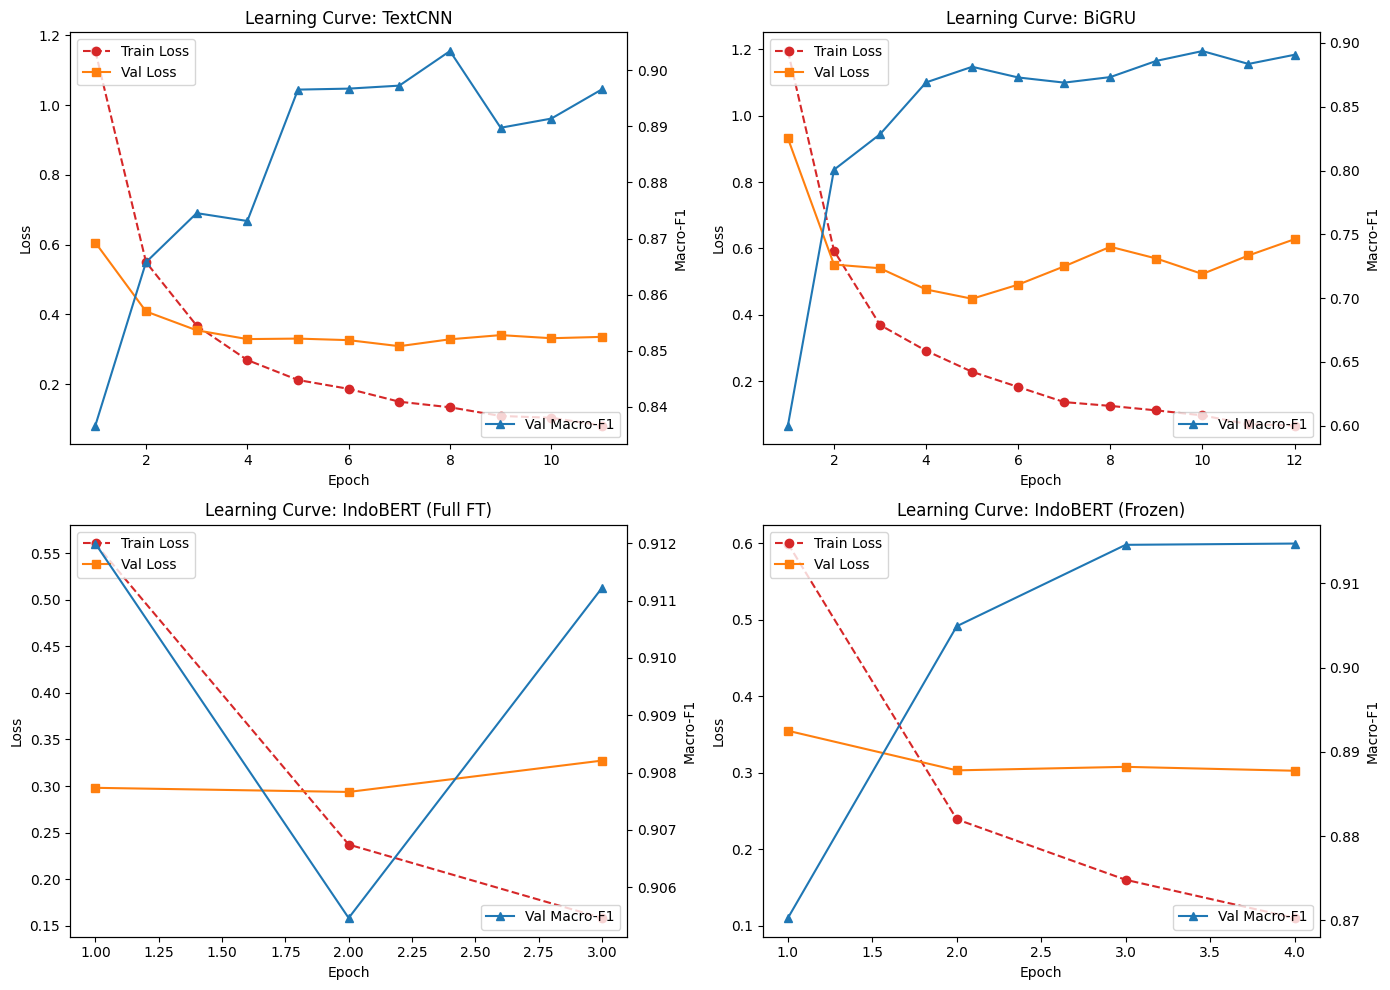

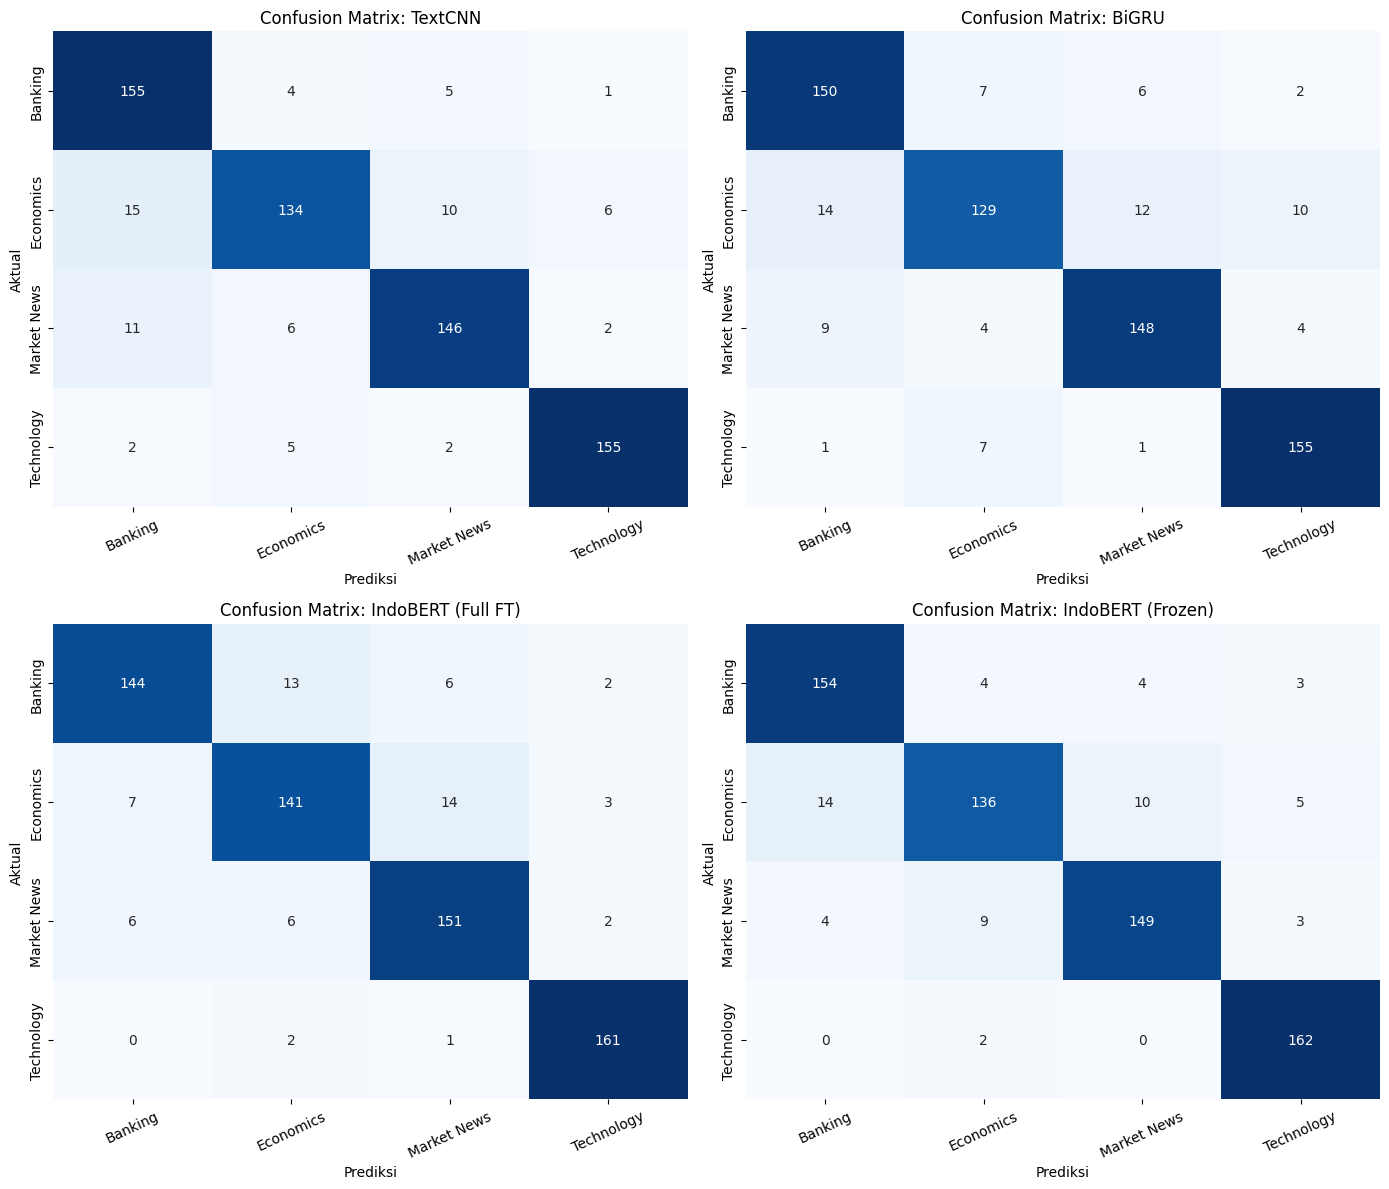

In [26]:
# ==============================================================================
# EVALUASI LENGKAP PADA TEST SET
# ==============================================================================

def prediksi_seq(model, loader):
    model.eval()
    preds, probs = [], []
    with torch.no_grad():
        for X_b, _ in loader:
            X_b = X_b.to(device)
            logits = model(X_b)
            prob = torch.softmax(logits, dim=1)
            preds.extend(logits.argmax(dim=1).cpu().numpy())
            probs.extend(prob.cpu().numpy())
    return np.array(preds), np.array(probs)

def prediksi_bert(model, loader):
    model.eval()
    preds, probs = [], []
    with torch.no_grad():
        for batch in loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            logits = model(input_ids=input_ids, attention_mask=attention_mask).logits
            prob = torch.softmax(logits, dim=1)
            preds.extend(logits.argmax(dim=1).cpu().numpy())
            probs.extend(prob.cpu().numpy())
    return np.array(preds), np.array(probs)

# Ambil Prediksi
pred_cnn, prob_cnn = prediksi_seq(cnn_model, test_seq_loader)
pred_bigru, prob_bigru = prediksi_seq(bigru_model, test_seq_loader)
pred_bert, prob_bert = prediksi_bert(bert_model, test_bert_loader)
pred_bert_frozen, prob_bert_frozen = prediksi_bert(bert_frozen_model, test_bert_loader)

hasil_prediksi = {
    "TextCNN": (pred_cnn, waktu_cnn, riwayat_cnn),
    "BiGRU": (pred_bigru, waktu_bigru, riwayat_bigru),
    "IndoBERT (Full FT)": (pred_bert, waktu_bert, riwayat_bert),
    "IndoBERT (Frozen)": (pred_bert_frozen, waktu_bert_frozen, riwayat_bert_frozen),
}

# 1. Tabel Komparasi
ringkasan_metrik = []
for nama, (preds, waktu, _) in hasil_prediksi.items():
    ringkasan_metrik.append({
        "Model": nama,
        "Accuracy (%)": round(accuracy_score(y_test, preds) * 100, 2),
        "Precision Macro (%)": round(precision_score(y_test, preds, average="macro") * 100, 2),
        "Recall Macro (%)": round(recall_score(y_test, preds, average="macro") * 100, 2),
        "F1 Macro (%)": round(f1_score(y_test, preds, average="macro") * 100, 2),
        "Waktu Training (s)": round(waktu, 1),
    })

df_evaluasi = pd.DataFrame(ringkasan_metrik).set_index("Model")
print("\n=== RINGKASAN PERFORMA 4 MODEL PADA TEST SET ===")
display(df_evaluasi)

# 2. Classification Report
for nama, (preds, _, _) in hasil_prediksi.items():
    print(f"\nClassification Report - {nama}:")
    print(classification_report(y_test, preds, target_names=nama_kelas, digits=4))

# 3. Learning Curves (Grid 2x2)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, (nama, (_, _, riw)) in zip(axes, hasil_prediksi.items()):
    ep = range(1, len(riw["train_loss"]) + 1)
    ax.plot(ep, riw["train_loss"], "o--", label="Train Loss", color="tab:red")
    ax.plot(ep, riw["val_loss"], "s-", label="Val Loss", color="tab:orange")
    ax2 = ax.twinx()
    ax2.plot(ep, riw["val_f1"], "^-", label="Val Macro-F1", color="tab:blue")
    ax.set_title(f"Learning Curve: {nama}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax2.set_ylabel("Macro-F1")
    ax.legend(loc="upper left")
    ax2.legend(loc="lower right")

plt.tight_layout()
plt.show()

# 4. Confusion Matrix (Grid 2x2)
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.flatten()

for ax, (nama, (preds, _, _)) in zip(axes, hasil_prediksi.items()):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=nama_kelas, yticklabels=nama_kelas,
        ax=ax, cbar=False
    )
    ax.set_title(f"Confusion Matrix: {nama}")
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Aktual")
    ax.tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

In [27]:
# ==============================================================================
# POIN 10 & 11: KESEPAKATAN ANTAR MODEL & ERROR ANALYSIS MODEL TERBAIK
# ==============================================================================

# 1. Kesepakatan Prediksi Antar Model (Pairwise Agreement)
print("=== TINGKAT KESEPAKATAN PREDIKSI ANTAR MODEL (TEST SET) ===")
for m1, m2 in combinations(hasil_prediksi.keys(), 2):
    p1, p2 = hasil_prediksi[m1][0], hasil_prediksi[m2][0]
    sepakat = (p1 == p2).mean() * 100
    print(f"  {m1:<22} vs {m2:<22} : {sepakat:.2f}% prediksi identik")

# 2. Pilih Model Terbaik berdasarkan Macro F1-score pada Test Set
prob_models = {
    "TextCNN": prob_cnn,
    "BiGRU": prob_bigru,
    "IndoBERT (Full FT)": prob_bert,
    "IndoBERT (Frozen)": prob_bert_frozen,
}
nama_terbaik = df_evaluasi["F1 Macro (%)"].idxmax()
pred_terbaik = hasil_prediksi[nama_terbaik][0]
prob_terbaik = prob_models[nama_terbaik]
print(f"\nModel Terbaik (Test Macro-F1 tertinggi): {nama_terbaik} ({df_evaluasi.loc[nama_terbaik, 'F1 Macro (%)']:.2f}%)")

# 3. Rekapitulasi Pasangan Kelas yang Paling Sering Tertukar pada Model Terbaik
test_analisis = test_df[["url", "title", "category", "teks_bersih"]].copy()
test_analisis["prediksi"] = [id2label[i] for i in pred_terbaik]
test_analisis["confidence_%"] = (prob_terbaik.max(axis=1) * 100).round(2)

salah_pred = test_analisis[test_analisis["category"] != test_analisis["prediksi"]].copy()
print(f"Total kesalahan prediksi {nama_terbaik}: {len(salah_pred)} dari {len(test_df)} artikel ({len(salah_pred)/len(test_df)*100:.2f}%)")

pasangan_salah = (
    salah_pred.groupby(["category", "prediksi"])
    .size()
    .reset_index(name="jumlah_kasus")
    .sort_values("jumlah_kasus", ascending=False)
)
print("\n=== Top Pasangan Kelas yang Paling Sering Salah Diklasifikasikan ===")
display(pasangan_salah.head(8))

# 4. Sampel Berita yang Salah Diklasifikasikan dengan Confidence Tinggi (Untuk Analisis Kualitatif Poin 11)
print(f"\n=== 8 Contoh Artikel yang Salah Diklasifikasikan oleh {nama_terbaik} (Confidence Tertinggi) ===")
kolom_tampil = ["title", "category", "prediksi", "confidence_%", "teks_bersih"]
display(salah_pred.sort_values("confidence_%", ascending=False)[kolom_tampil].head(8))

=== TINGKAT KESEPAKATAN PREDIKSI ANTAR MODEL (TEST SET) ===
  TextCNN                vs BiGRU                  : 92.72% prediksi identik
  TextCNN                vs IndoBERT (Full FT)     : 90.59% prediksi identik
  TextCNN                vs IndoBERT (Frozen)      : 92.26% prediksi identik
  BiGRU                  vs IndoBERT (Full FT)     : 90.14% prediksi identik
  BiGRU                  vs IndoBERT (Frozen)      : 91.35% prediksi identik
  IndoBERT (Full FT)     vs IndoBERT (Frozen)      : 93.02% prediksi identik

Model Terbaik (Test Macro-F1 tertinggi): IndoBERT (Frozen) (91.12%)
Total kesalahan prediksi IndoBERT (Frozen): 58 dari 659 artikel (8.80%)

=== Top Pasangan Kelas yang Paling Sering Salah Diklasifikasikan ===


,category,prediksi,jumlah_kasus
3,Economics,Banking,14
4,Economics,Market News,10
7,Market News,Economics,9
5,Economics,Technology,5
1,Banking,Market News,4
0,Banking,Economics,4
6,Market News,Banking,4
2,Banking,Technology,3



=== 8 Contoh Artikel yang Salah Diklasifikasikan oleh IndoBERT (Frozen) (Confidence Tertinggi) ===


,title,category,prediksi,confidence_%,teks_bersih
79,Sinners Akan Rilis Ulang di Imax untuk Hari Halloween,Banking,Technology,99.949997,"Sinners akan kembali ke bioskop Imax tepat pada hari Halloween. Dilansir dari laman variety, film box office dengan rating R yang disutradarai oleh Ryan Coogler dan dibintangi Michael B Jordan yan..."
154,Volkswagen Berencana Pangkas 4.000 Pekerja Imbas Tekanan pada Bisnis Porsche,Economics,Technology,99.940002,Volkswagen berencana kembali memangkas lebih dari 4.000 pekerja di Porsche sebagai bagian dari upaya restrukturisasi perusahaan. Surat kabar bisnis Jerman Handelsblatt melaporkan bahwa langkah ter...
635,Bank Jago (ARTO) Ungkap Dua Backbone di Balik Kinerja Bank Digital,Market News,Banking,99.699997,Semakin luas dan massifnya pemanfaatan kecerdasan buatan (aritificial intelligence/AI) di masyarakat terus memantik kekhawatiran sejumlah pihak atas dampak dari hadirnya perkembangan teknologi ter...
238,Harga Emas Antam Naik Rp23.000 Hari Ini,Economics,Market News,99.690002,"Harga emas batangan PT Aneka Tambang Tbk (Antam) naik pada perdagangan hari ini. Berdasarkan informasi dari situs resmi Logam Mulia, harga emas Antam meroket Rp23.000 menjadi Rp2.613.000 per gram ..."
239,Gibran Minta Dunia Pendidikan Link and Match dengan Industri Kendaraan Listrik,Economics,Technology,99.650002,Wakil Presiden (Wapres) Gibran Rakabuming menegaskan pentingnya memperkuat keterkaitan (link and match) antara dunia pendidikan dan industri untuk menyiapkan sumber daya manusia yang adaptif terha...
208,"Lima Tahun Holding UMi, Layani 33,8 Juta Debitur Aktif dan Dorong 2,3 Juta Nasabah Naik Kelas",Economics,Banking,99.589996,"Berjalan selama lima tahun, Holding Ultra Mikro (UMi) yang mengintegrasikan PT Bank Rakyat Indonesia (Persero) Tbk (BBRI), PT Pegadaian, dan PT Permodalan Nasional Madani (PNM) mencatatkan capaian..."
194,XLSMART (EXCL) Bidik Jaringan 5G Jangkau 88 Kabupaten/Kota pada Akhir 2026,Market News,Technology,99.570000,PT XLSMART Telecom Sejahtera Tbk (EXCL) terus memperluas jaringan 5G di Indonesia. Perseroan menargetkan jaringan tersebut bisa menjangkau 88 kabupaten/kota hingga akhir dari saat ini sebanyak 50 ...
275,Purbaya: Perang Timur Tengah Kerek Imbal Hasil SBN dan Surat Utang Sejumlah Negara,Market News,Economics,99.480003,"Menteri Keuangan (Menkeu) Purbaya Yudhi Sadewa mengatakan eskalasi konflik Timur Tengah turut berdampak pada kinerja pasar Surat Berharga Negara (SBN). Dia mengatakan, imbal hasil atau yield SBN s..."


## Pembahasan Perbandingan Model & Error Analysis (Poin 10 & 11)

### Perbandingan Performa Model (Poin 10)
Berdasarkan evaluasi pada data testing (659 artikel):
1. **IndoBERT (Frozen 8-Layer)** menjadi model dengan performa terbaik (**Accuracy 91,20%**, **Macro-F1 91,12%**), diikuti oleh **IndoBERT (Full Fine-Tuning)** (**Accuracy 90,59%**, **Macro-F1 90,57%**), **TextCNN** (**Accuracy 89,53%**, **Macro-F1 89,49%**), dan **BiGRU** (**Accuracy 88,32%**, **Macro-F1 88,22%**).
2. **Mengapa Transformer (IndoBERT) mengungguli CNN dan BiGRU?**
   - IndoBERT telah melalui proses *pre-training* pada korpus bahasa Indonesia yang besar sehingga sudah memiliki representasi semantik dan sintaksis kontekstual, sedangkan `TextCNN` dan `BiGRU` memulai dari embedding acak yang hanya dilatih pada 3.070 artikel train.
3. **Mengapa IndoBERT (Frozen 8-Layer) lebih baik daripada IndoBERT (Full Fine-Tuning)?**
   - Dengan ukuran dataset latih yang relatif moderat (3.070 artikel), *full fine-tuning* memperbarui seluruh 124,4 juta parameter sehingga lebih mudah mengalami *overfitting* terhadap pola spesifik data latih.
   - Membekukan *embedding* dan 8 layer encoder terbawah (hanya melatih 23,26% parameter pada 4 layer teratas + *classifier*) menjaga representasi bahasa umum tetap stabil sambil menyesuaikan fitur tingkat tinggi ke domain berita IDX Channel.
4. **Mengapa TextCNN sedikit mengungguli BiGRU?**
   - Klasifikasi topik berita sangat bergantung pada frasa/n-gram kunci (misal nama bank, istilah kredit, indeks saham, atau istilah teknologi) yang dapat ditangkap langsung secara lokal oleh filter konvolusi `kernel_size=(3,4,5)` pada `TextCNN`, sementara `BiGRU` memproses urutan token panjang (300 token) dari nol sehingga lebih sulit konvergen optimal pada data berukuran sedang.

### Error Analysis Model Terbaik (Poin 11)
Pada data uji (659 artikel), model terbaik (**IndoBERT Frozen**) membuat **58 kesalahan prediksi (8,80%)**, dengan pasangan kelas yang paling sering tertukar yaitu **Economics → Banking (14 kasus)**, **Economics → Market News (10 kasus)**, dan **Market News → Economics (9 kasus)**. Secara umum, kesalahan terjadi karena:
- **Tumpang-tindih topik antar kanal**: Berita kebijakan perbankan/suku bunga sering membahas aspek makroekonomi sekaligus emiten bank (`Economics` ↔ `Banking`), atau berita aksi korporasi bank/perusahaan teknologi masuk ke kanal `Market News`.
- ***Label noise* dari kanal portal berita (*distant supervision*)**: Pada contoh kesalahan dengan *confidence* tertinggi (>99%), ditemukan artikel yang memang kurang tepat penempatan kanalnya di situs sumber, seperti *"Sinners Akan Rilis Ulang di Imax untuk Hari Halloween"* (berlabel `Banking`, diprediksi `Technology` 99,95%) dan *"Harga Emas Antam Naik Rp23.000 Hari Ini"* (berlabel `Economics`, diprediksi `Market News` 99,69%).
- **Batas panjang input (`MAX_LEN_BERT = 256`)**: Pada artikel yang sangat panjang, konteks penjelas di paragraf akhir terpotong sehingga model hanya melihat bagian awal artikel.